BASE_DIR: C:\Users\Lennon\Documents\GitHub\Group-4-Assignment-2-Two-


,district_id,pop_2025,male_2025,female_2025,under_15,age_15_64,age_65_plus,sex_ratio_m_per_100f,youth_dependency_ratio,old_age_dependency_ratio
0,D05,152444,71858,80586,19766,113748,18930,89.169335,17.377009,16.642051
1,D24,172718,83990,88728,16717,108176,47825,94.660085,15.453520,44.210361


Saved: C:\Users\Lennon\Documents\GitHub\Group-4-Assignment-2-Two-\outputs\part1a_ratios_d05_d24.csv
Saved: C:\Users\Lennon\Documents\GitHub\Group-4-Assignment-2-Two-\outputs\part1a_pyramids_d05_d24.png


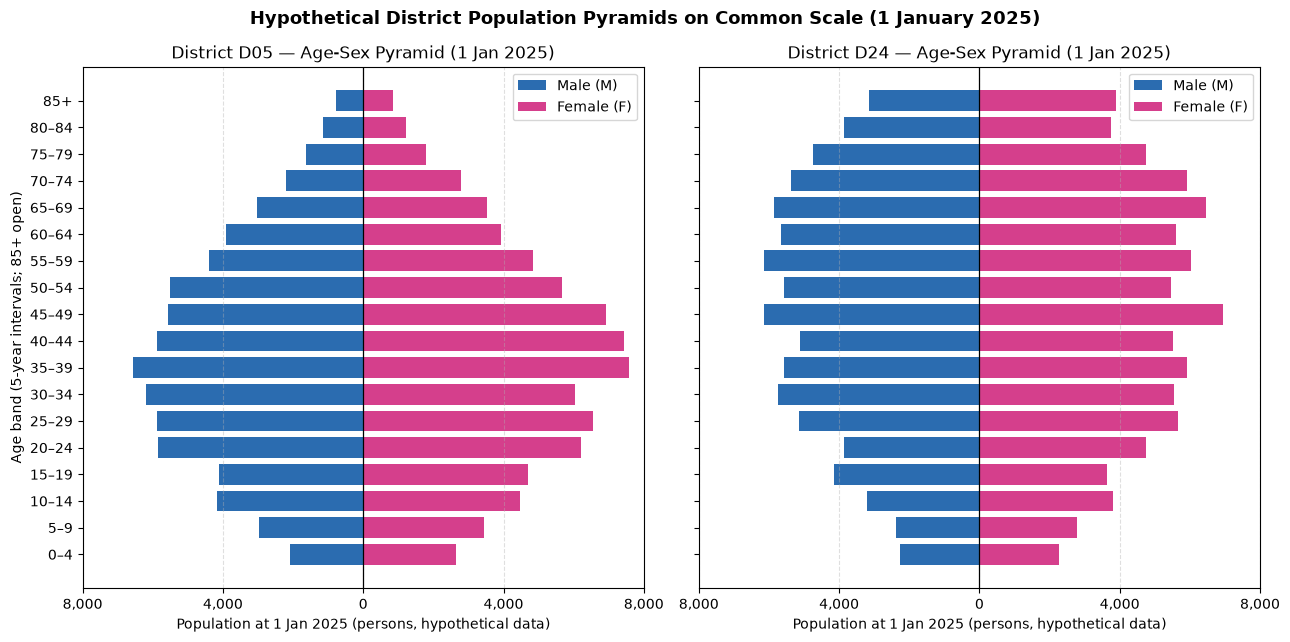

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline

# ---------- Paths ----------
def find_base_dir():
    env = os.environ.get("PROJECT_DIR")
    if env and (Path(env) / "data" / "raw").exists():
        return Path(env)

    start = Path.cwd().resolve()
    for p in [start, *start.parents]:
        if (p / "data" / "raw").exists():
            return p

    try:
        import tkinter as tk
        from tkinter import filedialog
        root = tk.Tk()
        root.withdraw()
        root.attributes("-topmost", True)
        chosen = filedialog.askdirectory(title="Select the project folder (the one containing data/raw)")
        root.destroy()
    except Exception:
        chosen = input("Paste the project folder path (the one containing data/raw): ").strip().strip('"')

    if chosen and (Path(chosen) / "data" / "raw").exists():
        return Path(chosen)
    raise FileNotFoundError("data/raw not found in the selected folder.")

BASE_DIR = find_base_dir()
RAW_DIR = BASE_DIR / "data" / "raw"
OUT_DIR = BASE_DIR / "outputs"
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("BASE_DIR:", BASE_DIR)

def safe_save(save_fn, filename):
    """Try OUT_DIR first; if the OS rejects the write, fall back to the home folder."""
    try:
        save_fn(OUT_DIR / filename)
        print("Saved:", OUT_DIR / filename)
    except OSError as e:
        fallback = Path.home() / "part1a_outputs"
        fallback.mkdir(exist_ok=True)
        save_fn(fallback / filename)
        print(f"Could not write to {OUT_DIR} ({e}).\nSaved to {fallback / filename} instead.")

# ---------- Data ----------
age_sex = pd.read_csv(RAW_DIR / "age_sex.csv")

selected_districts = ["D05", "D24"]
age_order = [0, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60, 65, 70, 75, 80, 85]
age_labels = {
    0: "0–4", 5: "5–9", 10: "10–14", 15: "15–19", 20: "20–24", 25: "25–29",
    30: "30–34", 35: "35–39", 40: "40–44", 45: "45–49", 50: "50–54", 55: "55–59",
    60: "60–64", 65: "65–69", 70: "70–74", 75: "75–79", 80: "80–84", 85: "85+"
}

# ---------- 1. Ratios at 1 January 2025 ----------
ratio_rows = []
for d_id in selected_districts:
    sub = age_sex[age_sex["district_id"] == d_id]
    tot = sub["population_2025"].sum()
    m_pop = sub.loc[sub["sex"] == "M", "population_2025"].sum()
    f_pop = sub.loc[sub["sex"] == "F", "population_2025"].sum()
    u15 = sub.loc[sub["age_start"] < 15, "population_2025"].sum()
    w15_64 = sub.loc[(sub["age_start"] >= 15) & (sub["age_start"] < 65), "population_2025"].sum()
    o65p = sub.loc[sub["age_start"] >= 65, "population_2025"].sum()

    ratio_rows.append({
        "district_id": d_id,
        "pop_2025": tot,
        "male_2025": m_pop,
        "female_2025": f_pop,
        "under_15": u15,
        "age_15_64": w15_64,
        "age_65_plus": o65p,
        "sex_ratio_m_per_100f": (m_pop / f_pop) * 100.0,
        "youth_dependency_ratio": (u15 / w15_64) * 100.0,
        "old_age_dependency_ratio": (o65p / w15_64) * 100.0,
    })

ratios_df = pd.DataFrame(ratio_rows)
display(ratios_df)
safe_save(lambda p: ratios_df.to_csv(p, index=False), "part1a_ratios_d05_d24.csv")

# ---------- 2. Common-scale population pyramids ----------
piv = age_sex[age_sex["district_id"].isin(selected_districts)].pivot_table(
    index="age_start", columns=["district_id", "sex"], values="population_2025", aggfunc="sum"
).reindex(age_order)

x_lim = np.ceil(piv.max().max() / 2000.0) * 2000.0

fig, axes = plt.subplots(1, 2, figsize=(13, 6.5), sharey=True)
y_pos = np.arange(len(age_order))
y_names = [age_labels[a] for a in age_order]

for ax, d_id in zip(axes, selected_districts):
    m_vals = piv[(d_id, "M")].values
    f_vals = piv[(d_id, "F")].values
    ax.barh(y_pos, -m_vals, height=0.78, color="#2b6cb0", label="Male (M)")
    ax.barh(y_pos, f_vals, height=0.78, color="#d53f8c", label="Female (F)")
    ax.axvline(0, color="black", linewidth=0.9)
    ax.set_xlim(-x_lim, x_lim)
    ticks = np.linspace(-x_lim, x_lim, 5)
    ax.set_xticks(ticks)
    ax.set_xticklabels([f"{abs(int(t)):,}" for t in ticks])
    ax.set_xlabel("Population at 1 Jan 2025 (persons, hypothetical data)")
    ax.set_title(f"District {d_id} — Age-Sex Pyramid (1 Jan 2025)")
    ax.grid(axis="x", linestyle="--", alpha=0.4)
    ax.legend(loc="upper right")

axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(y_names)
axes[0].set_ylabel("Age band (5-year intervals; 85+ open)")

fig.suptitle("Hypothetical District Population Pyramids on Common Scale (1 January 2025)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
safe_save(lambda p: fig.savefig(p, dpi=150), "part1a_pyramids_d05_d24.png")
plt.show()

BASE_DIR: C:\Users\Lennon\Documents\Dummy Run
